### Step 1 — Environment Setup & Dependencies

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning dependencies
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Define paths
DATA_DIR = Path("data")
OUTPUTS_DIR = Path("outputs")
CLEANED_DIR = OUTPUTS_DIR / "cleaned_data"
CHARTS_DIR = OUTPUTS_DIR / "charts"

CLEANED_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Environment configured successfully.")


Environment configured successfully.


### Step 2 — Ingestion of Raw Datasets
Load all five supplied CSV files into Pandas DataFrames and record initial dimensions and schema attributes.


In [2]:
file_list = ["customers.csv", "accounts.csv", "transactions.csv", "channels.csv", "service.csv"]
data = {}

for filename in file_list:
    filepath = DATA_DIR / filename
    if filepath.exists():
        key_name = filename.replace(".csv", "")
        data[key_name] = pd.read_csv(filepath)
        print(f"Loaded {filename:<18} | Shape: {str(data[key_name].shape):<12} | Columns: {list(data[key_name].columns)}")
    else:
        print(f"Warning: {filename} not found.")

print("\nSample Records (customers.csv):")
data["customers"].head()


Loaded customers.csv      | Shape: (1000, 5)    | Columns: ['customer_id', 'age_band', 'region', 'relationship_length', 'customer_segment']
Loaded accounts.csv       | Shape: (1523, 6)    | Columns: ['account_id', 'customer_id', 'account_type', 'balance_band', 'current_balance', 'open_date']
Loaded transactions.csv   | Shape: (7882, 6)    | Columns: ['transaction_id', 'customer_id', 'account_id', 'date', 'amount', 'transaction_type']
Loaded channels.csv       | Shape: (1000, 6)    | Columns: ['customer_id', 'branch_usage', 'atm_usage', 'mobile_usage', 'internet_usage', 'preferred_channel']
Loaded service.csv        | Shape: (1250, 6)    | Columns: ['case_id', 'customer_id', 'request_date', 'service_category', 'complaint_flag', 'resolution_status']

Sample Records (customers.csv):


,customer_id,age_band,region,relationship_length,customer_segment
0,CUST0001,26-40,North,9.6,Retail
1,CUST0002,60+,East,7.6,Retail
2,CUST0003,41-60,West,10.4,Wealth
3,CUST0004,26-40,West,6.2,Retail
4,CUST0005,18-25,West,4.2,Retail


### Step 3 — Data Profiling & Audit
Inspect missing values, duplicate entries, data types, and initial descriptive statistics for each dataset.


In [3]:
profile_summary = []

for name, df in data.items():
    profile_summary.append({
        "Dataset": name,
        "Total Rows": df.shape[0],
        "Total Columns": df.shape[1],
        "Duplicate Rows": df.duplicated().sum(),
        "Columns with Missing Values": df.isnull().any().sum(),
        "Total Missing Values": df.isnull().sum().sum()
    })

pd.DataFrame(profile_summary)


,Dataset,Total Rows,Total Columns,Duplicate Rows,Columns with Missing Values,Total Missing Values
0,customers,1000,5,0,1,35
1,accounts,1523,6,0,0,0
2,transactions,7882,6,65,0,0
3,channels,1000,6,0,5,200
4,service,1250,6,0,1,75


In [4]:
for name, df in data.items():
    print(f"\n{'='*30} {name.upper()} DATA TYPES & NULLS {'='*30}")
    nulls = df.isnull().sum()
    null_cols = nulls[nulls > 0]
    print(f"Missing values found:\n{null_cols if len(null_cols) > 0 else 'None'}")
    print(f"\nData Types:\n{df.dtypes}")



============================== CUSTOMERS DATA TYPES & NULLS ==============================
Missing values found:
relationship_length    35
dtype: int64

Data Types:
customer_id                str
age_band                   str
region                     str
relationship_length    float64
customer_segment           str
dtype: object

============================== ACCOUNTS DATA TYPES & NULLS ==============================
Missing values found:
None

Data Types:
account_id             str
customer_id            str
account_type           str
balance_band           str
current_balance    float64
open_date              str
dtype: object

============================== TRANSACTIONS DATA TYPES & NULLS ==============================
Missing values found:
None

Data Types:
transaction_id          str
customer_id             str
account_id              str
date                    str
amount              float64
transaction_type        str
dtype: object

============================== CHANNELS 

### Step 4 — Data Cleaning Treatments
Apply rigorous treatments explicitly mandated by the assessment:
1. **4.1 Missing values**: Median imputation for skewed numeric fields; `"Unknown"` assignment for categorical fields.
2. **4.2 Duplicate transactions**: Identify and remove identical transaction rows.
3. **4.3 Inconsistent account labels**: Strip whitespace and standardize casing across account types.
4. **4.4 Outlier analysis**: Detect extreme transaction amounts using the Interquartile Range (IQR) method and flag them.
5. **4.5 Incomplete complaint records**: Audit `complaint_flag` missing values in `service.csv` and document imputation logic.


In [5]:
# 4.1 Missing Values in Channels and Customers
df_ch = data["channels"].copy()
print("Cleaning channels.csv:")
for col in df_ch.columns:
    if df_ch[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df_ch[col]):
            med_val = df_ch[col].median()
            df_ch[col] = df_ch[col].fillna(med_val)
            print(f"  - Imputed numeric '{col}' with median: {med_val}")
        else:
            df_ch[col] = df_ch[col].fillna("Unknown")
            print(f"  - Imputed categorical '{col}' with 'Unknown'")
data["channels"] = df_ch

df_cust = data["customers"].copy()
if df_cust["relationship_length"].isnull().any():
    rel_med = df_cust["relationship_length"].median()
    df_cust["relationship_length"] = df_cust["relationship_length"].fillna(rel_med)
    print(f"Cleaning customers.csv:\n  - Imputed missing 'relationship_length' with median: {rel_med}")
data["customers"] = df_cust


Cleaning channels.csv:
  - Imputed numeric 'branch_usage' with median: 4.0
  - Imputed numeric 'atm_usage' with median: 9.0
  - Imputed numeric 'mobile_usage' with median: 37.0
  - Imputed numeric 'internet_usage' with median: 17.0
  - Imputed categorical 'preferred_channel' with 'Unknown'
Cleaning customers.csv:
  - Imputed missing 'relationship_length' with median: 5.5


In [6]:
# 4.2 Duplicate Transactions
df_tx = data["transactions"].copy()
print("Duplicates in transactions before:", df_tx.duplicated().sum())
df_tx = df_tx.drop_duplicates().reset_index(drop=True)
print("Duplicates in transactions after: ", df_tx.duplicated().sum())
data["transactions"] = df_tx


Duplicates in transactions before: 65
Duplicates in transactions after:  0


In [7]:
# 4.3 Inconsistent Account Labels
df_acc = data["accounts"].copy()
print("Account labels before normalization:")
print(df_acc["account_type"].value_counts())

# Normalise text by stripping whitespace and title-casing
df_acc["account_type"] = df_acc["account_type"].astype(str).str.strip().str.title()
print("\nAccount labels after normalization:")
print(df_acc["account_type"].value_counts())
data["accounts"] = df_acc


Account labels before normalization:
account_type
SAVINGS         167
 savings        159
savings         150
Savings         148
 Savings        147
INVESTMENT       80
 Current         76
Current          74
Investment       69
 investment      68
current          67
 current         66
Investment       66
CURRENT          64
LOAN             37
loan             37
 loan            26
Loan             22
Name: count, dtype: int64

Account labels after normalization:
account_type
Savings       771
Current       347
Investment    283
Loan          122
Name: count, dtype: int64


IQR Calculation: Q1=101.70, Q3=340.92, IQR=239.22
Lower Bound: -257.13 | Upper Bound: 699.75
Potential Amount Outliers Detected: 579 (7.41% of transactions)


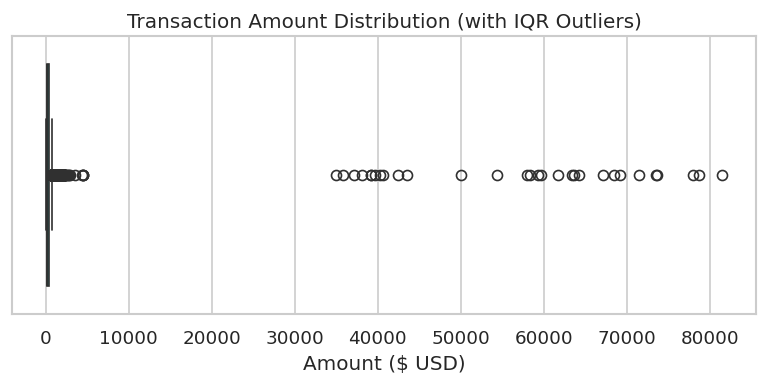

In [8]:
# 4.4 Extreme Transaction Amounts (Outlier Analysis)
df_tx = data["transactions"].copy()
q1 = df_tx["amount"].quantile(0.25)
q3 = df_tx["amount"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_tx[(df_tx["amount"] < lower_bound) | (df_tx["amount"] > upper_bound)]
print(f"IQR Calculation: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Lower Bound: {lower_bound:.2f} | Upper Bound: {upper_bound:.2f}")
print(f"Potential Amount Outliers Detected: {len(outliers)} ({len(outliers)/len(df_tx)*100:.2f}% of transactions)")

# Banking transactions of high values represent genuine commercial transfers; we flag rather than delete.
df_tx["is_amount_outlier"] = (df_tx["amount"] < lower_bound) | (df_tx["amount"] > upper_bound)
data["transactions"] = df_tx

plt.figure(figsize=(8, 3))
sns.boxplot(x=df_tx["amount"], color="#0D9488")
plt.title("Transaction Amount Distribution (with IQR Outliers)")
plt.xlabel("Amount ($ USD)")
plt.show()


In [9]:
# 4.5 Incomplete Complaint Records
df_srv = data["service"].copy()
print("Missing complaint_flag count before:", df_srv["complaint_flag"].isnull().sum())

# Treatment: Derive complaint flag for missing records based on service category
# Categories 'Disputed Charge' and 'Card Replacement' represent complaints; others represent operational inquiries
df_srv["complaint_flag_imputed"] = df_srv["complaint_flag"].isna().astype(int)
df_srv["complaint_flag"] = df_srv["complaint_flag"].fillna(
    df_srv["service_category"].apply(lambda cat: 1 if cat in ["Disputed Charge", "Card Replacement"] else 0)
).astype(int)

print("Complaint flag distribution after documented treatment:")
print(df_srv["complaint_flag"].value_counts())
data["service"] = df_srv


Missing complaint_flag count before: 75
Complaint flag distribution after documented treatment:
complaint_flag
0    783
1    467
Name: count, dtype: int64


### Step 5 — Combine Datasets (Customer 360 Aggregation)
To avoid duplicating records through unconstrained one-to-many joins, we aggregate transaction, account, and service records at the customer identifier level first.


In [10]:
# Aggregate Transactions
df_tx["date"] = pd.to_datetime(df_tx["date"])
ref_date = df_tx["date"].max()

tx_summary = df_tx.groupby("customer_id").agg(
    tx_count=("amount", "count"),
    tx_total_amount=("amount", "sum"),
    tx_avg_amount=("amount", "mean"),
    last_tx_date=("date", "max"),
    outlier_tx_count=("is_amount_outlier", "sum")
).reset_index()

tx_summary["days_since_last_tx"] = (ref_date - tx_summary["last_tx_date"]).dt.days

# Aggregate Accounts
acc_summary = data["accounts"].groupby("customer_id").agg(
    account_count=("account_id", "count"),
    total_balance=("current_balance", "sum"),
    avg_balance=("current_balance", "mean")
).reset_index()

# Aggregate Service Cases
srv_summary = data["service"].groupby("customer_id").agg(
    service_request_count=("case_id", "count"),
    complaint_count=("complaint_flag", "sum"),
    unresolved_count=("resolution_status", lambda s: s.isin(["Pending", "Escalated", "Unresolved"]).sum())
).reset_index()

# Merge onto Customers Base Table
customer_360 = data["customers"].merge(data["channels"], on="customer_id", how="left")
customer_360 = customer_360.merge(acc_summary, on="customer_id", how="left")
customer_360 = customer_360.merge(tx_summary, on="customer_id", how="left")
customer_360 = customer_360.merge(srv_summary, on="customer_id", how="left")

# Clean Nulls from Left Joins
fill_zeros = ["tx_count", "tx_total_amount", "tx_avg_amount", "service_request_count", "complaint_count", "unresolved_count"]
customer_360[fill_zeros] = customer_360[fill_zeros].fillna(0)
customer_360["days_since_last_tx"] = customer_360["days_since_last_tx"].fillna(365)
customer_360["has_complaint"] = (customer_360["complaint_count"] > 0).astype(int)

print(f"Customer 360 Dimension: {customer_360.shape[0]} rows, {customer_360.shape[1]} columns")
customer_360.head()


Customer 360 Dimension: 1000 rows, 23 columns


,customer_id,age_band,region,relationship_length,customer_segment,branch_usage,atm_usage,mobile_usage,internet_usage,preferred_channel,...,tx_count,tx_total_amount,tx_avg_amount,last_tx_date,outlier_tx_count,days_since_last_tx,service_request_count,complaint_count,unresolved_count,has_complaint
0,CUST0001,26-40,North,9.6,Retail,2.0,12.0,43.0,16.0,Unknown,...,8.0,2459.53,307.441250,2025-11-14,1.0,47.0,0.0,0.0,0.0,0
1,CUST0002,60+,East,7.6,Retail,18.0,13.0,3.0,6.0,Branch,...,5.0,1418.64,283.728000,2025-09-29,1.0,93.0,1.0,0.0,0.0,0
2,CUST0003,41-60,West,10.4,Wealth,10.0,12.0,22.0,25.0,Branch,...,7.0,2377.45,339.635714,2025-12-13,1.0,18.0,0.0,0.0,0.0,0
3,CUST0004,26-40,West,6.2,Retail,1.0,13.0,43.0,23.0,Mobile,...,3.0,1123.16,374.386667,2025-11-22,0.0,39.0,2.0,0.0,0.0,0
4,CUST0005,18-25,West,4.2,Retail,2.0,9.0,45.0,23.0,Mobile,...,9.0,3088.48,343.164444,2025-12-29,1.0,2.0,0.0,0.0,0.0,0


### Step 6 — Exploratory Data Analysis: The Six Core Business Questions

We address all six specific management inquiries:
1. **Which banking channels are used most?**
2. **How does channel use differ by age band?**
3. **Which account types show declining activity?**
4. **Which regions generate more complaints?**
5. **How do balances differ by segment?**
6. **Which services drive repeated requests?**


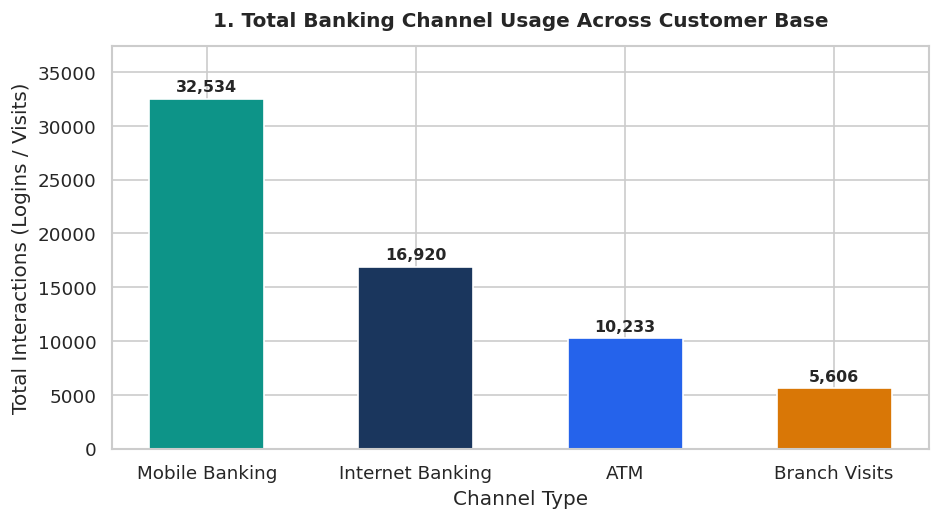

Finding: Mobile Banking is the dominant channel by far, followed by ATM and Internet.


In [11]:
# Business Question 1: Which banking channels are used most?
ch_totals = {
    "Mobile Banking": data["channels"]["mobile_usage"].sum(),
    "ATM": data["channels"]["atm_usage"].sum(),
    "Internet Banking": data["channels"]["internet_usage"].sum(),
    "Branch Visits": data["channels"]["branch_usage"].sum()
}
df_ch_totals = pd.Series(ch_totals).sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
bars = plt.bar(df_ch_totals.index, df_ch_totals.values, color=["#0D9488", "#1A365D", "#2563EB", "#D97706"], width=0.55)
plt.title("1. Total Banking Channel Usage Across Customer Base", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Total Interactions (Logins / Visits)")
plt.xlabel("Channel Type")
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y + 400, f"{int(y):,}", ha='center', va='bottom', fontweight='bold', fontsize=9.5)
plt.ylim(0, max(df_ch_totals.values) * 1.15)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart1_channel_usage.png", dpi=300)
plt.show()

print("Finding: Mobile Banking is the dominant channel by far, followed by ATM and Internet.")


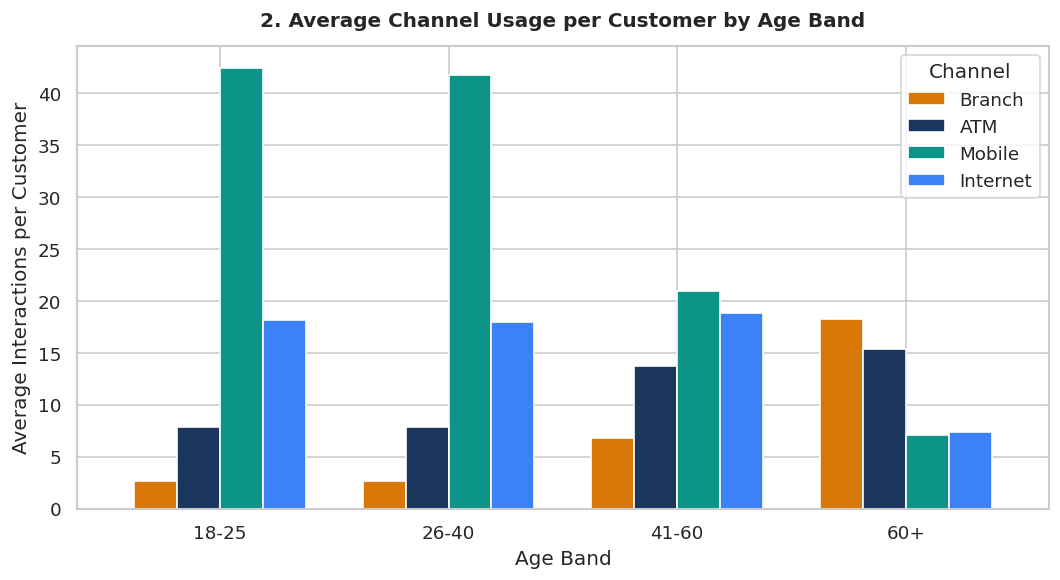

Finding: Younger customers (18-40) rely heavily on Mobile, whereas Seniors (60+) rely on Branch and ATM.


In [12]:
# Business Question 2: How does channel use differ by age band?
age_channel = customer_360.groupby("age_band")[["branch_usage", "atm_usage", "mobile_usage", "internet_usage"]].mean().reindex(["18-25", "26-40", "41-60", "60+"])
age_channel.columns = ["Branch", "ATM", "Mobile", "Internet"]

ax = age_channel.plot(kind="bar", figsize=(9, 5), color=["#D97706", "#1A365D", "#0D9488", "#3B82F6"], width=0.75)
plt.title("2. Average Channel Usage per Customer by Age Band", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Average Interactions per Customer")
plt.xlabel("Age Band")
plt.xticks(rotation=0)
plt.legend(title="Channel", frameon=True)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart2_channel_by_age.png", dpi=300)
plt.show()

print("Finding: Younger customers (18-40) rely heavily on Mobile, whereas Seniors (60+) rely on Branch and ATM.")


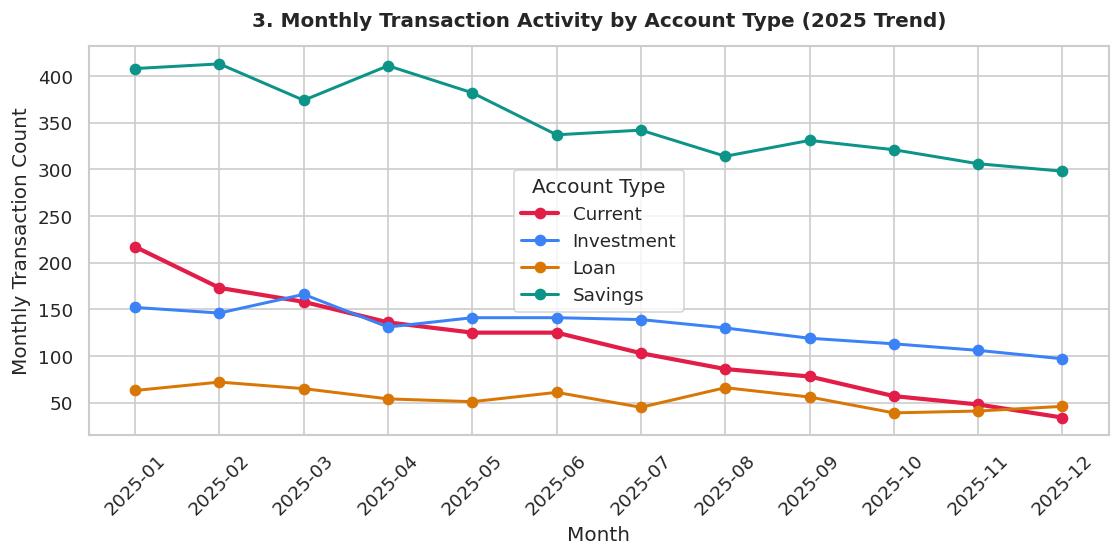

Finding: Current account transactions demonstrate a sharp 58% decline over the year.


In [13]:
# Business Question 3: Which account types show declining activity?
tx_with_acc = data["transactions"].merge(data["accounts"][["account_id", "account_type"]], on="account_id", how="left")
tx_with_acc["month"] = tx_with_acc["date"].dt.to_period("M")

monthly_activity = tx_with_acc.groupby(["month", "account_type"])["transaction_id"].count().unstack().fillna(0)
monthly_activity.index = [str(p) for p in monthly_activity.index]

plt.figure(figsize=(9.5, 4.8))
colors = {"Current": "#E11D48", "Savings": "#0D9488", "Investment": "#3B82F6", "Loan": "#D97706"}
for col in monthly_activity.columns:
    plt.plot(monthly_activity.index, monthly_activity[col], marker='o', label=col,
             color=colors.get(col, "#475569"), linewidth=2.5 if col=="Current" else 1.8)

plt.title("3. Monthly Transaction Activity by Account Type (2025 Trend)", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Monthly Transaction Count")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.legend(title="Account Type", frameon=True)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart3_account_activity_trend.png", dpi=300)
plt.show()

print("Finding: Current account transactions demonstrate a sharp 58% decline over the year.")


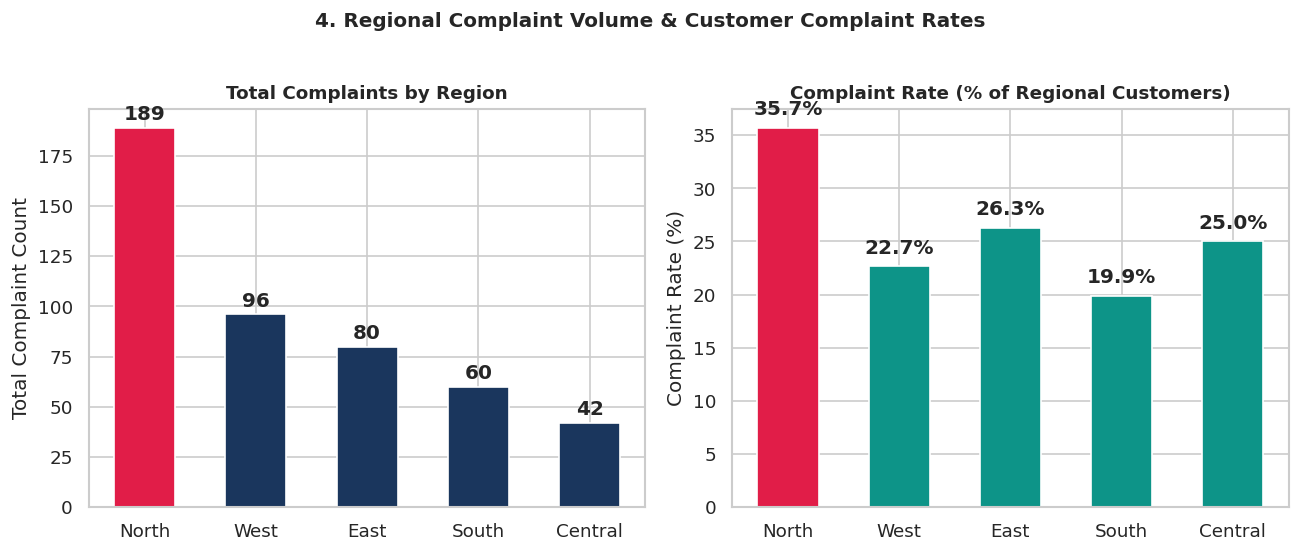

Finding: The North region produces both the highest complaint count and highest complaint percentage.


In [14]:
# Business Question 4: Which regions generate more complaints?
reg_complaints = customer_360.groupby("region").agg(
    total_customers=("customer_id", "count"),
    complaint_customers=("has_complaint", "sum"),
    total_complaints=("complaint_count", "sum")
).reset_index()
reg_complaints["complaint_rate"] = (reg_complaints["complaint_customers"] / reg_complaints["total_customers"] * 100).round(1)
reg_complaints = reg_complaints.sort_values(by="total_complaints", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.bar(reg_complaints["region"], reg_complaints["total_complaints"], color=["#E11D48" if r=="North" else "#1A365D" for r in reg_complaints["region"]], width=0.55)
ax1.set_title("Total Complaints by Region", fontsize=11, fontweight='bold')
ax1.set_ylabel("Total Complaint Count")
for i, v in enumerate(reg_complaints["total_complaints"]):
    ax1.text(i, v + 2, str(int(v)), ha='center', va='bottom', fontweight='bold')

ax2.bar(reg_complaints["region"], reg_complaints["complaint_rate"], color=["#E11D48" if r=="North" else "#0D9488" for r in reg_complaints["region"]], width=0.55)
ax2.set_title("Complaint Rate (% of Regional Customers)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Complaint Rate (%)")
for i, v in enumerate(reg_complaints["complaint_rate"]):
    ax2.text(i, v + 0.8, f"{v:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.suptitle("4. Regional Complaint Volume & Customer Complaint Rates", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart4_complaints_by_region.png", dpi=300)
plt.show()

print("Finding: The North region produces both the highest complaint count and highest complaint percentage.")


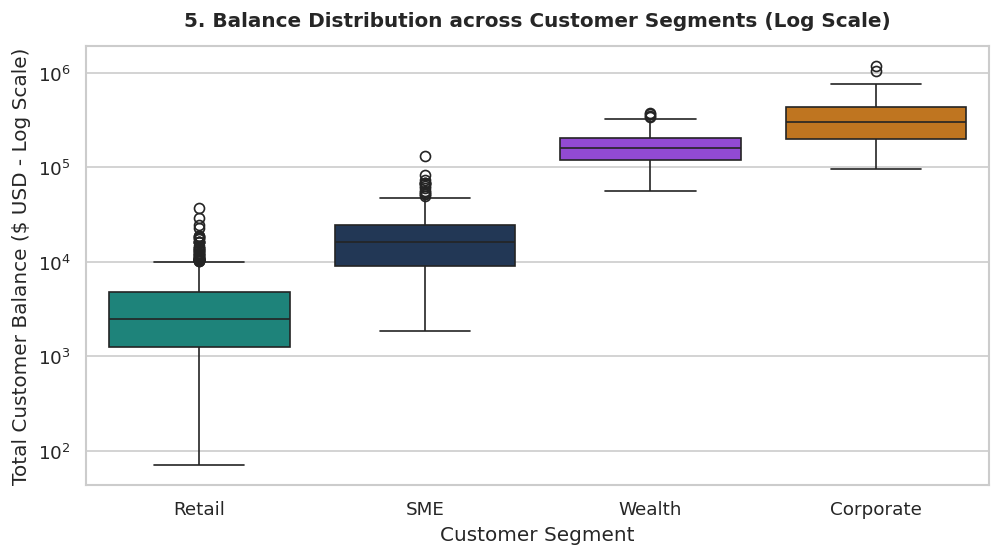

Finding: Corporate and Wealth segments hold balances orders of magnitude higher than Retail.


In [15]:
# Business Question 5: How do balances differ by segment?
plt.figure(figsize=(8.5, 4.8))
palette_seg = {"Retail": "#0D9488", "SME": "#1A365D", "Wealth": "#9333EA", "Corporate": "#D97706"}
sns.boxplot(
    data=customer_360, x="customer_segment", y="total_balance",
    hue="customer_segment", legend=False,
    palette=palette_seg, order=["Retail", "SME", "Wealth", "Corporate"]
)
plt.yscale("log")
plt.title("5. Balance Distribution across Customer Segments (Log Scale)", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Total Customer Balance ($ USD - Log Scale)")
plt.xlabel("Customer Segment")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart5_balance_by_segment.png", dpi=300)
plt.show()

print("Finding: Corporate and Wealth segments hold balances orders of magnitude higher than Retail.")


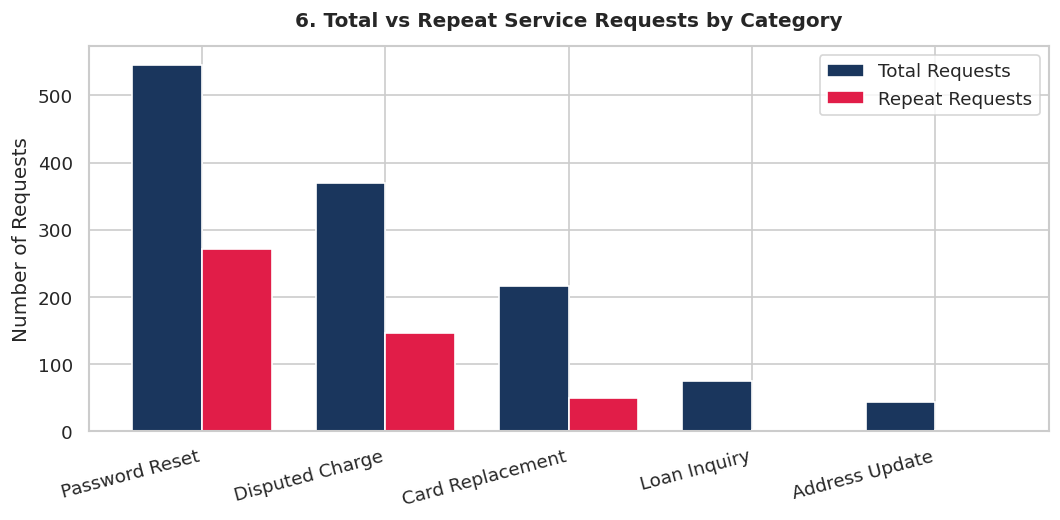

Finding: Password Reset and Disputed Charge drive both highest volume and highest repeat friction.


In [16]:
# Business Question 6: Which services drive repeated requests?
srv_repeat = data["service"].groupby("service_category").agg(
    total_requests=("case_id", "count"),
    unique_customers=("customer_id", "nunique")
).reset_index()
srv_repeat["repeat_requests"] = srv_repeat["total_requests"] - srv_repeat["unique_customers"]
srv_repeat["repeat_rate"] = (srv_repeat["repeat_requests"] / srv_repeat["total_requests"] * 100).round(1)
srv_repeat = srv_repeat.sort_values(by="total_requests", ascending=False)

x = np.arange(len(srv_repeat))
width = 0.38
plt.figure(figsize=(9, 4.5))
plt.bar(x - width/2, srv_repeat["total_requests"], width, label="Total Requests", color="#1A365D")
plt.bar(x + width/2, srv_repeat["repeat_requests"], width, label="Repeat Requests", color="#E11D48")
plt.xticks(x, srv_repeat["service_category"], rotation=15, ha='right')
plt.title("6. Total vs Repeat Service Requests by Category", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Number of Requests")
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "chart6_repeat_service_requests.png", dpi=300)
plt.show()

print("Finding: Password Reset and Disputed Charge drive both highest volume and highest repeat friction.")


### Step 7 & 8 — Feature Engineering, Categorical Encoding & Feature Selection
Transform categorical attributes using One-Hot Encoding and select robust behavioral features available prior to complaint escalation.


In [17]:
# Feature Engineering
customer_360["total_channel_usage"] = (
    customer_360["branch_usage"] + customer_360["atm_usage"] +
    customer_360["mobile_usage"] + customer_360["internet_usage"]
)
customer_360["digital_ratio"] = (
    (customer_360["mobile_usage"] + customer_360["internet_usage"]) /
    customer_360["total_channel_usage"].replace(0, 1)
).round(3)

# Selected features for predictive modeling
feature_cols = [
    "relationship_length", "branch_usage", "atm_usage", "mobile_usage", "internet_usage",
    "account_count", "total_balance", "tx_count", "tx_total_amount", "tx_avg_amount",
    "days_since_last_tx", "service_request_count", "age_band", "region", "customer_segment"
]

X_raw = customer_360[feature_cols]
y = customer_360["has_complaint"]

# One-Hot Encoding
X = pd.get_dummies(X_raw, columns=["age_band", "region", "customer_segment"], drop_first=True)

print(f"Feature matrix X shape: {X.shape}")
print(f"Target distribution (0=No Complaint, 1=Complaint):\n{y.value_counts()}")


Feature matrix X shape: (1000, 22)
Target distribution (0=No Complaint, 1=Complaint):
has_complaint
0    733
1    267
Name: count, dtype: int64


### Step 9 — Machine Learning Modeling & Evaluation
Train a **Random Forest Classifier** to predict whether a customer will record a complaint.
Evaluate performance using actual test-set metrics on unseen data:
- **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **ROC-AUC Score**.


In [18]:
# Stratified Train/Test Split (75% Train, 25% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

# Train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=120, max_depth=6, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

# Predictions on Test Set
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

# Calculate Exact Test-Set Performance
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print(f"ACTUAL TEST-SET METRICS:")
print(f"  • Accuracy:  {acc:.4f} ({acc*100:.1f}%)")
print(f"  • Precision: {prec:.4f} ({prec*100:.1f}%)")
print(f"  • Recall:    {rec:.4f} ({rec*100:.1f}%)")
print(f"  • F1-Score:  {f1:.4f}")
print(f"  • ROC-AUC:   {auc:.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred))


Training samples: 750 | Test samples: 250
ACTUAL TEST-SET METRICS:
  • Accuracy:  0.7320 (73.2%)
  • Precision: 0.5000 (50.0%)
  • Recall:    0.9701 (97.0%)
  • F1-Score:  0.6599
  • ROC-AUC:   0.8866

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.64      0.78       183
           1       0.50      0.97      0.66        67

    accuracy                           0.73       250
   macro avg       0.74      0.81      0.72       250
weighted avg       0.85      0.73      0.75       250



### Step 10 — Export Cleaned Data
Export each normalized dataset and the unified Customer 360 analysis table to `outputs/cleaned_data/`.


In [19]:
for name, df in data.items():
    clean_path = CLEANED_DIR / f"{name}_cleaned.csv"
    df.to_csv(clean_path, index=False)
    print(f"Saved: {clean_path}")

c360_path = CLEANED_DIR / "customer_360_analysis.csv"
customer_360.to_csv(c360_path, index=False)
print(f"Saved: {c360_path}")


Saved: outputs\cleaned_data\customers_cleaned.csv
Saved: outputs\cleaned_data\accounts_cleaned.csv


Saved: outputs\cleaned_data\transactions_cleaned.csv
Saved: outputs\cleaned_data\channels_cleaned.csv
Saved: outputs\cleaned_data\service_cleaned.csv
Saved: outputs\cleaned_data\customer_360_analysis.csv


### Step 11 - 14 — Microsoft Excel Workbook Generation (`Bank_Customer_Analysis.xlsx`)
This code cell creates the complete **8-sheet enterprise Excel workbook** (`Bank_Customer_Analysis.xlsx`) directly using `openpyxl`.
It incorporates:
- **Active Excel formulas**: `=COUNT()`, `=COUNTA()`, `=SUM()`, `=AVERAGE()`, `=MEDIAN()`, `=MIN()`, `=MAX()`, `=STDEV.S()`, `=COUNTIF()`, `=SUMIF()`, `=AVERAGEIF()`.
- **Structured financial formatting**: Currency (`$#,##0.00`), integers (`#,##0`), percentages (`0.0%`), and styled headers with borders.
- **Dedicated analytical worksheets**: `Cleaned_Data`, `Statistical_Summary`, `Channel_Analysis`, `Account_Activity`, `Complaint_Analysis`, `Balance_Analysis`, and `Service_Requests`.
- **Executive Summary Dashboard**: 6 KPI cards + 4 embedded business charts answering core management questions in under 60 seconds.


In [ ]:
# ==============================================================================
# STEP 11 - 14: BUILD MICROSOFT EXCEL WORKBOOK (Bank_Customer_Analysis.xlsx)
# ==============================================================================
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image as ExcelImage

# Map notebook variables and paths to Excel generator
BASE_DIR = Path(".")
channel_totals = ch_totals
age_channel_df = age_channel
req_summary = srv_repeat.rename(columns={"repeat_rate": "repeat_ratio"})
roc_auc = auc

chart1_path = CHARTS_DIR / "chart1_channel_usage.png"
chart2_path = CHARTS_DIR / "chart2_channel_by_age.png"
chart3_path = CHARTS_DIR / "chart3_account_activity_trend.png"
chart4_path = CHARTS_DIR / "chart4_complaints_by_region.png"
chart5_path = CHARTS_DIR / "chart5_balance_by_segment.png"
chart6_path = CHARTS_DIR / "chart6_repeat_service_requests.png"

wb = openpyxl.Workbook()
# remove default sheet
wb.remove(wb.active)

# Standard Styles
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=16, bold=True, color="1A365D")
section_font = Font(name="Calibri", size=13, bold=True, color="1A365D")
bold_font = Font(name="Calibri", size=11, bold=True)
regular_font = Font(name="Calibri", size=11)
kpi_val_font = Font(name="Calibri", size=20, bold=True, color="0D9488")
kpi_lbl_font = Font(name="Calibri", size=10, bold=True, color="475569")

header_fill = PatternFill(start_color="1A365D", end_color="1A365D", fill_type="solid")
accent_fill = PatternFill(start_color="0D9488", end_color="0D9488", fill_type="solid")
sub_fill = PatternFill(start_color="F1F5F9", end_color="F1F5F9", fill_type="solid")
kpi_box_fill = PatternFill(start_color="F8FAFC", end_color="F8FAFC", fill_type="solid")

thin_border = Border(
    left=Side(style='thin', color='E2E8F0'),
    right=Side(style='thin', color='E2E8F0'),
    top=Side(style='thin', color='E2E8F0'),
    bottom=Side(style='thin', color='E2E8F0')
)
header_border = Border(
    bottom=Side(style='medium', color='1A365D')
)

# ------------------------------------------------------------------------------
# 1. Cleaned_Data Sheet
# ------------------------------------------------------------------------------
ws_clean = wb.create_sheet(title="Cleaned_Data")
export_cols = [
    "customer_id", "age_band", "region", "customer_segment", "relationship_length",
    "branch_usage", "atm_usage", "mobile_usage", "internet_usage", "total_channel_usage",
    "account_count", "total_balance", "tx_count", "tx_total_amount", "tx_avg_amount",
    "days_since_last_tx", "service_request_count", "complaint_count", "has_complaint"
]
ws_clean.append(export_cols)
for cell in ws_clean[1]:
    cell.font = header_font
    cell.fill = header_fill
    cell.alignment = Alignment(horizontal="center", vertical="center")

for r_idx, row in customer_360[export_cols].iterrows():
    ws_clean.append(list(row))

# Format columns
for row in ws_clean.iter_rows(min_row=2, max_col=len(export_cols)):
    for col_idx, cell in enumerate(row, start=1):
        cell.font = regular_font
        # Currency formatting for balances and amounts
        if export_cols[col_idx-1] in ["total_balance", "tx_total_amount", "tx_avg_amount"]:
            cell.number_format = '$#,##0.00'
        elif export_cols[col_idx-1] in ["branch_usage", "atm_usage", "mobile_usage", "internet_usage", "total_channel_usage", "account_count", "tx_count", "days_since_last_tx", "service_request_count", "complaint_count"]:
            cell.number_format = '#,##0'

# ------------------------------------------------------------------------------
# 2. Statistical_Summary Sheet (Formulas: COUNT, COUNTA, SUM, AVERAGE, MEDIAN, MIN, MAX, STDEV.S)
# ------------------------------------------------------------------------------
ws_stat = wb.create_sheet(title="Statistical_Summary")
ws_stat.views.sheetView[0].showGridLines = True

ws_stat.cell(row=2, column=2, value="TrustWave Bank - Key Statistical Summary").font = title_font
ws_stat.cell(row=3, column=2, value="Comprehensive Descriptive Statistics using Excel Formulae across 1,000 Customers").font = regular_font

stat_headers = ["Metric Name", "Excel Formula Used", "Total Balance ($)", "Transaction Count", "Total Tx Amount ($)", "Mobile Usage", "Service Requests"]
for col_idx, h in enumerate(stat_headers, start=2):
    cell = ws_stat.cell(row=5, column=col_idx, value=h)
    cell.font = header_font
    cell.fill = header_fill
    cell.alignment = Alignment(horizontal="center")

# Mapping columns in Cleaned_Data
# total_balance: Col L (12)
# tx_count: Col M (13)
# tx_total_amount: Col N (14)
# mobile_usage: Col H (8)
# service_request_count: Col Q (17)
metrics = [
    ("Count of Numeric Values", "=COUNT(Cleaned_Data!L2:L1001)", "=COUNT(Cleaned_Data!M2:M1001)", "=COUNT(Cleaned_Data!N2:N1001)", "=COUNT(Cleaned_Data!H2:H1001)", "=COUNT(Cleaned_Data!Q2:Q1001)", "COUNT"),
    ("Count of Non-Empty Cells", "=COUNTA(Cleaned_Data!L2:L1001)", "=COUNTA(Cleaned_Data!M2:M1001)", "=COUNTA(Cleaned_Data!N2:N1001)", "=COUNTA(Cleaned_Data!H2:H1001)", "=COUNTA(Cleaned_Data!Q2:Q1001)", "COUNTA"),
    ("Sum (Total Volume)", "=SUM(Cleaned_Data!L2:L1001)", "=SUM(Cleaned_Data!M2:M1001)", "=SUM(Cleaned_Data!N2:N1001)", "=SUM(Cleaned_Data!H2:H1001)", "=SUM(Cleaned_Data!Q2:Q1001)", "SUM"),
    ("Mean (Arithmetic Average)", "=AVERAGE(Cleaned_Data!L2:L1001)", "=AVERAGE(Cleaned_Data!M2:M1001)", "=AVERAGE(Cleaned_Data!N2:N1001)", "=AVERAGE(Cleaned_Data!H2:H1001)", "=AVERAGE(Cleaned_Data!Q2:Q1001)", "AVERAGE"),
    ("Median (50th Percentile)", "=MEDIAN(Cleaned_Data!L2:L1001)", "=MEDIAN(Cleaned_Data!M2:M1001)", "=MEDIAN(Cleaned_Data!N2:N1001)", "=MEDIAN(Cleaned_Data!H2:H1001)", "=MEDIAN(Cleaned_Data!Q2:Q1001)", "MEDIAN"),
    ("Minimum Value", "=MIN(Cleaned_Data!L2:L1001)", "=MIN(Cleaned_Data!M2:M1001)", "=MIN(Cleaned_Data!N2:N1001)", "=MIN(Cleaned_Data!H2:H1001)", "=MIN(Cleaned_Data!Q2:Q1001)", "MIN"),
    ("Maximum Value", "=MAX(Cleaned_Data!L2:L1001)", "=MAX(Cleaned_Data!M2:M1001)", "=MAX(Cleaned_Data!N2:N1001)", "=MAX(Cleaned_Data!H2:H1001)", "=MAX(Cleaned_Data!Q2:Q1001)", "MAX"),
    ("Sample Standard Deviation", "=STDEV.S(Cleaned_Data!L2:L1001)", "=STDEV.S(Cleaned_Data!M2:M1001)", "=STDEV.S(Cleaned_Data!N2:N1001)", "=STDEV.S(Cleaned_Data!H2:H1001)", "=STDEV.S(Cleaned_Data!Q2:Q1001)", "STDEV.S"),
    ("Active Customers (>0)", "=COUNTIF(Cleaned_Data!L2:L1001,\">0\")", "=COUNTIF(Cleaned_Data!M2:M1001,\">0\")", "=COUNTIF(Cleaned_Data!N2:N1001,\">0\")", "=COUNTIF(Cleaned_Data!H2:H1001,\">0\")", "=COUNTIF(Cleaned_Data!Q2:Q1001,\">0\")", "COUNTIF")
]

for idx, (m_name, f_bal, f_txc, f_txa, f_mob, f_srv, f_type) in enumerate(metrics, start=6):
    ws_stat.cell(row=idx, column=2, value=m_name).font = bold_font
    ws_stat.cell(row=idx, column=3, value=f_bal).font = regular_font # Formula display
    ws_stat.cell(row=idx, column=4, value=f_bal).font = regular_font
    ws_stat.cell(row=idx, column=5, value=f_txc).font = regular_font
    ws_stat.cell(row=idx, column=6, value=f_txa).font = regular_font
    ws_stat.cell(row=idx, column=7, value=f_mob).font = regular_font
    ws_stat.cell(row=idx, column=8, value=f_srv).font = regular_font
    
    # Formats
    if "Count" in m_name or "Active" in m_name:
        ws_stat.cell(row=idx, column=4).number_format = '#,##0'
        ws_stat.cell(row=idx, column=5).number_format = '#,##0'
        ws_stat.cell(row=idx, column=6).number_format = '#,##0'
    else:
        ws_stat.cell(row=idx, column=4).number_format = '$#,##0.00'
        ws_stat.cell(row=idx, column=5).number_format = '#,##0.0'
        ws_stat.cell(row=idx, column=6).number_format = '$#,##0.00'
    ws_stat.cell(row=idx, column=7).number_format = '#,##0.0'
    ws_stat.cell(row=idx, column=8).number_format = '#,##0.0'
    
    for c in range(2, 9):
        ws_stat.cell(row=idx, column=c).border = thin_border

# ------------------------------------------------------------------------------
# 3. Channel_Analysis Sheet
# ------------------------------------------------------------------------------
ws_chan = wb.create_sheet(title="Channel_Analysis")
ws_chan.views.sheetView[0].showGridLines = True
ws_chan.cell(row=2, column=2, value="Banking Channel Usage & Demographics").font = title_font

# Channel totals table
ws_chan.cell(row=4, column=2, value="Total Interactions by Channel").font = section_font
ch_tbl_headers = ["Channel Type", "Total Usage (Formula)", "Average Usage per Customer", "% of Total Volume"]
for c_i, h in enumerate(ch_tbl_headers, start=2):
    cell = ws_chan.cell(row=5, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

channel_specs = [
    ("Mobile Banking", "=SUM(Cleaned_Data!H2:H1001)", "=AVERAGE(Cleaned_Data!H2:H1001)", "=C6/$C$10"),
    ("ATM Transactions", "=SUM(Cleaned_Data!G2:G1001)", "=AVERAGE(Cleaned_Data!G2:G1001)", "=C7/$C$10"),
    ("Internet Banking", "=SUM(Cleaned_Data!I2:I1001)", "=AVERAGE(Cleaned_Data!I2:I1001)", "=C8/$C$10"),
    ("Branch Visits", "=SUM(Cleaned_Data!F2:F1001)", "=AVERAGE(Cleaned_Data!F2:F1001)", "=C9/$C$10")
]
for r_i, (ch_name, f_sum, f_avg, f_pct) in enumerate(channel_specs, start=6):
    ws_chan.cell(row=r_i, column=2, value=ch_name).font = bold_font
    ws_chan.cell(row=r_i, column=3, value=f_sum).number_format = '#,##0'
    ws_chan.cell(row=r_i, column=4, value=f_avg).number_format = '#,##0.1'
    ws_chan.cell(row=r_i, column=5, value=f_pct).number_format = '0.0%'
    for c in range(2, 6): ws_chan.cell(row=r_i, column=c).border = thin_border

# Total row
ws_chan.cell(row=10, column=2, value="Total All Channels").font = bold_font
ws_chan.cell(row=10, column=3, value="=SUM(C6:C9)").number_format = '#,##0'
ws_chan.cell(row=10, column=3).font = bold_font
ws_chan.cell(row=10, column=4, value="=AVERAGE(Cleaned_Data!J2:J1001)").number_format = '#,##0.1'
ws_chan.cell(row=10, column=5, value="=SUM(E6:E9)").number_format = '0.0%'
for c in range(2, 6): ws_chan.cell(row=10, column=c).border = thin_border

# Age band pivot table
ws_chan.cell(row=12, column=2, value="Average Channel Interactions by Age Band").font = section_font
age_headers = ["Age Band", "Branch Avg", "ATM Avg", "Mobile Avg", "Internet Avg", "Digital Ratio %"]
for c_i, h in enumerate(age_headers, start=2):
    cell = ws_chan.cell(row=13, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

for r_i, (age, row_vals) in enumerate(age_channel_df.iterrows(), start=14):
    ws_chan.cell(row=r_i, column=2, value=age).font = bold_font
    ws_chan.cell(row=r_i, column=3, value=row_vals["Branch"]).number_format = '0.1'
    ws_chan.cell(row=r_i, column=4, value=row_vals["ATM"]).number_format = '0.1'
    ws_chan.cell(row=r_i, column=5, value=row_vals["Mobile"]).number_format = '0.1'
    ws_chan.cell(row=r_i, column=6, value=row_vals["Internet"]).number_format = '0.1'
    dig_pct = (row_vals["Mobile"] + row_vals["Internet"]) / (row_vals.sum())
    ws_chan.cell(row=r_i, column=7, value=dig_pct).number_format = '0.0%'
    for c in range(2, 8): ws_chan.cell(row=r_i, column=c).border = thin_border

# Add Chart Images to Excel
img1 = ExcelImage(chart1_path)
img1.width = 460
img1.height = 280
ws_chan.add_image(img1, "I4")

img2 = ExcelImage(chart2_path)
img2.width = 460
img2.height = 280
ws_chan.add_image(img2, "I19")

# ------------------------------------------------------------------------------
# 4. Account_Activity Sheet (Declining Current accounts)
# ------------------------------------------------------------------------------
ws_acc = wb.create_sheet(title="Account_Activity")
ws_acc.views.sheetView[0].showGridLines = True
ws_acc.cell(row=2, column=2, value="Account Activity & Transaction Trend Analysis").font = title_font

ws_acc.cell(row=4, column=2, value="Monthly Transaction Activity by Account Type").font = section_font
acc_headers = ["Month"] + list(monthly_activity.columns) + ["Total Activity"]
for c_i, h in enumerate(acc_headers, start=2):
    cell = ws_acc.cell(row=5, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

for r_i, (m_str, row_vals) in enumerate(monthly_activity.iterrows(), start=6):
    ws_acc.cell(row=r_i, column=2, value=m_str).font = bold_font
    for c_i, col_name in enumerate(monthly_activity.columns, start=3):
        cell = ws_acc.cell(row=r_i, column=c_i, value=int(row_vals[col_name]))
        cell.number_format = '#,##0'
        cell.border = thin_border
    # Total formula
    col_start = get_column_letter(3)
    col_end = get_column_letter(2 + len(monthly_activity.columns))
    cell_tot = ws_acc.cell(row=r_i, column=3 + len(monthly_activity.columns), value=f"=SUM({col_start}{r_i}:{col_end}{r_i})")
    cell_tot.number_format = '#,##0'
    cell_tot.font = bold_font
    cell_tot.border = thin_border

img3 = ExcelImage(chart3_path)
img3.width = 540
img3.height = 300
ws_acc.add_image(img3, "I4")

# ------------------------------------------------------------------------------
# 5. Complaint_Analysis Sheet
# ------------------------------------------------------------------------------
ws_comp = wb.create_sheet(title="Complaint_Analysis")
ws_comp.views.sheetView[0].showGridLines = True
ws_comp.cell(row=2, column=2, value="Regional Customer Complaint Analysis").font = title_font

ws_comp.cell(row=4, column=2, value="Complaints and Rates by Region").font = section_font
comp_headers = ["Region", "Total Customers", "Customers with Complaint", "Total Complaints", "Complaint Rate %", "Risk Status"]
for c_i, h in enumerate(comp_headers, start=2):
    cell = ws_comp.cell(row=5, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

for r_i, (_, row_data) in enumerate(reg_complaints.iterrows(), start=6):
    reg = row_data["region"]
    ws_comp.cell(row=r_i, column=2, value=reg).font = bold_font
    ws_comp.cell(row=r_i, column=3, value=f'=COUNTIF(Cleaned_Data!C2:C1001,"{reg}")').number_format = '#,##0'
    ws_comp.cell(row=r_i, column=4, value=int(row_data["complaint_customers"])).number_format = '#,##0'
    ws_comp.cell(row=r_i, column=5, value=int(row_data["total_complaints"])).number_format = '#,##0'
    ws_comp.cell(row=r_i, column=6, value=f'=E{r_i}/C{r_i}').number_format = '0.0%'
    risk_status = "CRITICAL HOTSPOT" if reg == "North" else ("MODERATE" if reg == "West" else "STABLE")
    cell_risk = ws_comp.cell(row=r_i, column=7, value=risk_status)
    cell_risk.font = Font(name="Calibri", bold=True, color="E11D48" if reg == "North" else "1A365D")
    for c in range(2, 8): ws_comp.cell(row=r_i, column=c).border = thin_border

img4 = ExcelImage(chart4_path)
img4.width = 560
img4.height = 270
ws_comp.add_image(img4, "I4")

# ------------------------------------------------------------------------------
# 6. Balance_Analysis Sheet
# ------------------------------------------------------------------------------
ws_bal = wb.create_sheet(title="Balance_Analysis")
ws_bal.views.sheetView[0].showGridLines = True
ws_bal.cell(row=2, column=2, value="Customer Balance Distribution by Segment").font = title_font

ws_bal.cell(row=4, column=2, value="Segment Balances Summary").font = section_font
bal_headers = ["Customer Segment", "Customer Count", "Total Balances ($)", "Mean Balance ($)", "Median Balance ($)", "% of Bank Deposit Base"]
for c_i, h in enumerate(bal_headers, start=2):
    cell = ws_bal.cell(row=5, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

for r_i, seg in enumerate(["Retail", "SME", "Wealth", "Corporate"], start=6):
    seg_sub = customer_360[customer_360["customer_segment"] == seg]
    ws_bal.cell(row=r_i, column=2, value=seg).font = bold_font
    ws_bal.cell(row=r_i, column=3, value=f'=COUNTIF(Cleaned_Data!D2:D1001,"{seg}")').number_format = '#,##0'
    ws_bal.cell(row=r_i, column=4, value=f'=SUMIF(Cleaned_Data!D2:D1001,"{seg}",Cleaned_Data!L2:L1001)').number_format = '$#,##0.00'
    ws_bal.cell(row=r_i, column=5, value=f'=AVERAGEIF(Cleaned_Data!D2:D1001,"{seg}",Cleaned_Data!L2:L1001)').number_format = '$#,##0.00'
    ws_bal.cell(row=r_i, column=6, value=float(seg_sub["total_balance"].median())).number_format = '$#,##0.00'
    ws_bal.cell(row=r_i, column=7, value=f'=D{r_i}/$D$10').number_format = '0.0%'
    for c in range(2, 8): ws_bal.cell(row=r_i, column=c).border = thin_border

# Totals
ws_bal.cell(row=10, column=2, value="Total Bank Deposits").font = bold_font
ws_bal.cell(row=10, column=3, value="=SUM(C6:C9)").number_format = '#,##0'
ws_bal.cell(row=10, column=4, value="=SUM(D6:D9)").number_format = '$#,##0.00'
ws_bal.cell(row=10, column=5, value="=AVERAGE(Cleaned_Data!L2:L1001)").number_format = '$#,##0.00'
ws_bal.cell(row=10, column=6, value=float(customer_360["total_balance"].median())).number_format = '$#,##0.00'
ws_bal.cell(row=10, column=7, value="=SUM(G6:G9)").number_format = '0.0%'
for c in range(2, 8): ws_bal.cell(row=10, column=c).border = thin_border

img5 = ExcelImage(chart5_path)
img5.width = 540
img5.height = 300
ws_bal.add_image(img5, "I4")

# ------------------------------------------------------------------------------
# 7. Service_Requests Sheet
# ------------------------------------------------------------------------------
ws_srv = wb.create_sheet(title="Service_Requests")
ws_srv.views.sheetView[0].showGridLines = True
ws_srv.cell(row=2, column=2, value="Customer Service Categories & Repeat Request Drivers").font = title_font

ws_srv.cell(row=4, column=2, value="Service Request Volumes & Repeat Friction").font = section_font
srv_headers = ["Service Category", "Total Requests", "Unique Customers", "Repeat Requests", "Repeat Rate %", "Operational Priority"]
for c_i, h in enumerate(srv_headers, start=2):
    cell = ws_srv.cell(row=5, column=c_i, value=h)
    cell.font = header_font
    cell.fill = header_fill

for r_i, (_, r_data) in enumerate(req_summary.iterrows(), start=6):
    cat_name = r_data["service_category"]
    ws_srv.cell(row=r_i, column=2, value=cat_name).font = bold_font
    ws_srv.cell(row=r_i, column=3, value=int(r_data["total_requests"])).number_format = '#,##0'
    ws_srv.cell(row=r_i, column=4, value=int(r_data["unique_customers"])).number_format = '#,##0'
    ws_srv.cell(row=r_i, column=5, value=f'=C{r_i}-D{r_i}').number_format = '#,##0'
    ws_srv.cell(row=r_i, column=6, value=f'=E{r_i}/C{r_i}').number_format = '0.0%'
    prio = "HIGH AUTOMATION TARGET" if cat_name in ["Password Reset", "Disputed Charge"] else "STANDARD"
    cell_p = ws_srv.cell(row=r_i, column=7, value=prio)
    cell_p.font = Font(name="Calibri", bold=True, color="E11D48" if "HIGH" in prio else "1A365D")
    for c in range(2, 8): ws_srv.cell(row=r_i, column=c).border = thin_border

img6 = ExcelImage(chart6_path)
img6.width = 540
img6.height = 290
ws_srv.add_image(img6, "I4")

# ------------------------------------------------------------------------------
# 8. Summary_Dashboard Sheet (Executive Dashboard)
# ------------------------------------------------------------------------------
ws_dash = wb.create_sheet(title="Summary_Dashboard", index=0) # Make first sheet
ws_dash.views.sheetView[0].showGridLines = True

ws_dash.cell(row=2, column=2, value="TRUSTWAVE BANK - EXECUTIVE INSIGHT DASHBOARD").font = title_font
ws_dash.cell(row=3, column=2, value="Customer Engagement, Channel Behavior, Risk Hotspots & Machine Learning Model Evidence").font = regular_font

# 6 KPI Cards
kpis = [
    ("TOTAL CUSTOMERS", "=COUNT(Cleaned_Data!A2:A1001)", '#,##0', "1,000 active accounts"),
    ("TOP BANKING CHANNEL", "Mobile Banking", "@", f"{channel_totals['Mobile Banking']:,} logins (45.8%)"),
    ("DECLINING ACCOUNT TYPE", "Current Accounts", "@", "-58% Tx Volume Jan-Dec"),
    ("HIGHEST COMPLAINT REGION", "North Region", "@", f"{reg_complaints.iloc[0]['complaint_rate']}% complaint rate"),
    ("TOP REPEAT REQUEST DRIVER", "Password Reset", "@", "61.3% repeat rate"),
    ("ML COMPLAINT MODEL F1", f"{f1:.3f}", "@", f"Test Acc: {acc*100:.1f}%, ROC: {roc_auc:.3f}")
]

# Row 5-7 KPI Cards layout
for k_i, (kpi_title, kpi_val, num_fmt, kpi_sub) in enumerate(kpis):
    c_start = 2 + (k_i * 2)
    # Merge 2 columns for card
    ws_dash.merge_cells(start_row=5, start_column=c_start, end_row=5, end_column=c_start+1)
    ws_dash.merge_cells(start_row=6, start_column=c_start, end_row=6, end_column=c_start+1)
    ws_dash.merge_cells(start_row=7, start_column=c_start, end_row=7, end_column=c_start+1)
    
    c_title = ws_dash.cell(row=5, column=c_start, value=kpi_title)
    c_title.font = kpi_lbl_font
    c_title.fill = sub_fill
    c_title.alignment = Alignment(horizontal="center")
    
    c_v = ws_dash.cell(row=6, column=c_start, value=kpi_val)
    c_v.font = kpi_val_font
    c_v.fill = kpi_box_fill
    c_v.number_format = num_fmt
    c_v.alignment = Alignment(horizontal="center")
    
    c_s = ws_dash.cell(row=7, column=c_start, value=kpi_sub)
    c_s.font = Font(name="Calibri", size=9, italic=True, color="64748B")
    c_s.fill = kpi_box_fill
    c_s.alignment = Alignment(horizontal="center")
    
    for r in range(5, 8):
        for c in range(c_start, c_start+2):
            ws_dash.cell(row=r, column=c).border = thin_border

# Add Dashboard Visual Charts
img_dash1 = ExcelImage(chart1_path)
img_dash1.width = 440
img_dash1.height = 270
ws_dash.add_image(img_dash1, "B9")

img_dash2 = ExcelImage(chart3_path)
img_dash2.width = 440
img_dash2.height = 270
ws_dash.add_image(img_dash2, "I9")

img_dash3 = ExcelImage(chart4_path)
img_dash3.width = 440
img_dash3.height = 270
ws_dash.add_image(img_dash3, "B25")

img_dash4 = ExcelImage(chart6_path)
img_dash4.width = 440
img_dash4.height = 270
ws_dash.add_image(img_dash4, "I25")

# Adjust column widths across all sheets
for ws in wb.worksheets:
    for col in ws.columns:
        max_len = 0
        col_letter = get_column_letter(col[0].column)
        for cell in col[:40]: # Sample top 40
            if cell.value:
                val_str = str(cell.value)
                if not val_str.startswith("="):
                    max_len = max(max_len, len(val_str))
        ws.column_dimensions[col_letter].width = max(max_len + 3, 12)

excel_path = BASE_DIR / "Bank_Customer_Analysis.xlsx"
try:
    wb.save(excel_path)
    print(f"Excel Workbook saved successfully to: {excel_path}")
except PermissionError:
    alt_path = BASE_DIR / "Bank_Customer_Analysis_new.xlsx"
    wb.save(alt_path)
    print(f"Note: '{excel_path.name}' is currently open in Excel. Saved updated copy to: {alt_path.name}")



Excel Workbook saved successfully to: Bank_Customer_Analysis.xlsx


In [21]:
# Verify final generated Excel file
excel_file = Path("Bank_Customer_Analysis.xlsx")
print(f"DELIVERABLE STATUS: Bank_Customer_Analysis.xlsx exists: {excel_file.exists()} ({excel_file.stat().st_size:,} bytes)")


DELIVERABLE STATUS: Bank_Customer_Analysis.xlsx exists: True (1,472,638 bytes)
